In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
import pandas as pd
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)
tokenised_df=pd.read_csv("hugging_tokenised_df.csv")
untokenised_df=pd.read_csv("hugging_untokenised.csv")
validation_df=pd.read_csv('no_duplicate_validation.csv')
emotion=pd.read_csv('emotion_label_hugging.csv')

# BOW

In [34]:
from sklearn.feature_extraction.text import CountVectorizer

In [35]:
def Bow(data):
    bow=CountVectorizer()
    x_train=bow.fit_transform(data)
    return x_train,bow

In [36]:
bow_x_train,bow=Bow(untokenised_df["text"])
y_train=untokenised_df["label"]

In [37]:
print(bow_x_train)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 156288 stored elements and shape (15999, 12143)>
  Coords	Values
  (0, 7404)	1
  (0, 4029)	1
  (0, 5291)	1
  (1, 4029)	1
  (1, 1634)	1
  (1, 4636)	1
  (1, 9883)	2
  (1, 5221)	1
  (1, 2680)	1
  (1, 5219)	1
  (1, 11846)	1
  (1, 1691)	1
  (1, 905)	1
  (2, 4029)	1
  (2, 4680)	1
  (2, 6887)	1
  (2, 8264)	1
  (2, 4728)	1
  (2, 12022)	1
  (3, 4029)	1
  (3, 3763)	1
  (3, 7401)	1
  (3, 4130)	1
  (3, 11882)	1
  (3, 6056)	1
  :	:
  (15995, 11122)	1
  (15995, 11674)	1
  (15995, 10548)	1
  (15995, 2820)	1
  (15995, 10627)	1
  (15995, 10331)	1
  (15996, 4029)	1
  (15996, 4655)	1
  (15996, 10291)	1
  (15996, 7693)	1
  (15997, 4029)	1
  (15997, 6307)	1
  (15997, 4592)	1
  (15997, 10366)	1
  (15997, 9176)	1
  (15997, 2161)	1
  (15998, 7404)	1
  (15998, 4029)	1
  (15998, 1634)	1
  (15998, 9883)	1
  (15998, 6056)	1
  (15998, 6429)	1
  (15998, 1077)	1
  (15998, 10320)	1
  (15998, 8244)	1


In [38]:
print(bow)

CountVectorizer()


In [39]:
print(bow.get_feature_names_out())

['aa' 'aaaaaaand' 'aaaaand' ... 'zum' 'zumba' 'zz']


In [40]:
print(bow.get_feature_names_out()[905])


awake


##### validation data

In [41]:
x_val_text=validation_df["text"]
y_val_label=validation_df["label"]
x_val=bow.transform(x_val_text)

# TRAINING

In [42]:
def train(model):
    return model.fit(bow_x_train,y_train)

# Metric Function

In [43]:
def Metric(y_val,y_pred):
    accuracy=accuracy_score(y_val,y_pred)
    print("Accuracy=",accuracy)
    precision=precision_score(y_val,y_pred,average="weighted")
    print("precision=",precision)
    recall=recall_score(y_val,y_pred,average="weighted")
    print("recall=",recall)
    f1=f1_score(y_val,y_pred,average="weighted")
    print("F1 score=",f1)
    macro_f1=f1_score(y_val,y_pred,average="macro")
    print("macro F1 Score=",macro_f1)
    cm=confusion_matrix(y_val,y_pred)
    print("Confusion Matrix:")
    print(cm)
    cr=classification_report(y_val,y_pred)
    print("classification Report:")
    print(cr)

# Naive Bayes

In [44]:
from sklearn.naive_bayes import MultinomialNB
naive_bayes_model=MultinomialNB()
train(naive_bayes_model)
print(naive_bayes_model)

MultinomialNB()


## validation

In [45]:
y_pred_nb=naive_bayes_model.predict(x_val)

In [46]:
print(y_pred_nb)

[0 0 1 ... 1 1 1]


## metric

In [47]:
Metric(y_val_label,y_pred_nb)

Accuracy= 0.750501002004008
precision= 0.7621119164684768
recall= 0.750501002004008
F1 score= 0.7339456480768475
macro F1 Score= 0.6374832271276549
Confusion Matrix:
[[498  31   1  11   8   1]
 [ 63 607   6  14  10   3]
 [ 43  64  63   5   2   0]
 [ 40  30   1 193   8   2]
 [ 49  29   0  10 121   2]
 [ 36  18   0   2   9  16]]
classification Report:
              precision    recall  f1-score   support

           0       0.68      0.91      0.78       550
           1       0.78      0.86      0.82       703
           2       0.89      0.36      0.51       177
           3       0.82      0.70      0.76       274
           4       0.77      0.57      0.66       211
           5       0.67      0.20      0.30        81

    accuracy                           0.75      1996
   macro avg       0.77      0.60      0.64      1996
weighted avg       0.76      0.75      0.73      1996



# Logistic regression

In [48]:
from sklearn.linear_model import LogisticRegression
logistic_regression_model=LogisticRegression(max_iter=1000)
train(logistic_regression_model)
print(logistic_regression_model)

LogisticRegression(max_iter=1000)


In [49]:
y_train_lg_pred=logistic_regression_model.predict(bow_x_train)


## validation

In [50]:
y_pred_lr=logistic_regression_model.predict(x_val)

In [51]:
print(y_pred_lr)

[0 0 2 ... 1 2 1]


## metric

In [52]:
Metric(y_train,y_train_lg_pred)

Accuracy= 0.9732483280205013
precision= 0.9732084233535059
recall= 0.9732483280205013
F1 score= 0.9732007083664791
macro F1 Score= 0.9671569114033667
Confusion Matrix:
[[4569   44    6   28   18    1]
 [  31 5273   45    2    7    3]
 [   8   76 1216    2    2    0]
 [  47    5    0 2095   11    1]
 [  18    7    3   21 1876   12]
 [   3   10    0    0   17  542]]
classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      4666
           1       0.97      0.98      0.98      5361
           2       0.96      0.93      0.94      1304
           3       0.98      0.97      0.97      2159
           4       0.97      0.97      0.97      1937
           5       0.97      0.95      0.96       572

    accuracy                           0.97     15999
   macro avg       0.97      0.96      0.97     15999
weighted avg       0.97      0.97      0.97     15999



In [53]:
Metric(y_val_label,y_pred_lr)

Accuracy= 0.8306613226452906
precision= 0.8301762630213514
recall= 0.8306613226452906
F1 score= 0.8293842309435983
macro F1 Score= 0.7889814213868358
Confusion Matrix:
[[486  23   6  18  13   4]
 [ 40 614  26   9   7   7]
 [ 16  28 126   4   2   1]
 [ 22  14   2 232   4   0]
 [ 23  16   4  10 146  12]
 [ 10   9   0   1   7  54]]
classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.85       550
           1       0.87      0.87      0.87       703
           2       0.77      0.71      0.74       177
           3       0.85      0.85      0.85       274
           4       0.82      0.69      0.75       211
           5       0.69      0.67      0.68        81

    accuracy                           0.83      1996
   macro avg       0.80      0.78      0.79      1996
weighted avg       0.83      0.83      0.83      1996



# SVM

In [54]:
from sklearn.svm import SVC
svm_model=SVC()
train(svm_model)
print(svm_model)

SVC()


## validation

In [55]:
y_pred_svm=svm_model.predict(x_val)

In [56]:
print(y_pred_svm)

[0 0 1 ... 1 1 1]


## metric

In [57]:
Metric(y_val_label,y_pred_svm)

Accuracy= 0.7535070140280561
precision= 0.7792520674110599
recall= 0.7535070140280561
F1 score= 0.7406488751460074
macro F1 Score= 0.6771265832553363
Confusion Matrix:
[[455  72   4   7  11   1]
 [ 29 660   5   6   2   1]
 [ 23  83  68   1   2   0]
 [ 30  75   1 168   0   0]
 [ 28  51   0   9 123   0]
 [ 14  23   0   1  13  30]]
classification Report:
              precision    recall  f1-score   support

           0       0.79      0.83      0.81       550
           1       0.68      0.94      0.79       703
           2       0.87      0.38      0.53       177
           3       0.88      0.61      0.72       274
           4       0.81      0.58      0.68       211
           5       0.94      0.37      0.53        81

    accuracy                           0.75      1996
   macro avg       0.83      0.62      0.68      1996
weighted avg       0.78      0.75      0.74      1996



# Random forest

In [58]:
from sklearn.ensemble import RandomForestClassifier
random_forest_model=RandomForestClassifier()
train(random_forest_model)
print(random_forest_model)

RandomForestClassifier()


## validation

In [59]:
y_pred_rf=random_forest_model.predict(x_val)

In [60]:
print(y_pred_rf)

[0 0 2 ... 1 2 1]


## metric

In [61]:
Metric(y_val_label,y_pred_rf)

Accuracy= 0.8086172344689379
precision= 0.8102453114954354
recall= 0.8086172344689379
F1 score= 0.8069094513438919
macro F1 Score= 0.7712784946565021
Confusion Matrix:
[[486  30   6  14  11   3]
 [ 68 595  18   8  11   3]
 [ 13  34 123   4   2   1]
 [ 31  21   2 215   5   0]
 [ 24  16   0  15 148   8]
 [ 14   7   0   1  12  47]]
classification Report:
              precision    recall  f1-score   support

           0       0.76      0.88      0.82       550
           1       0.85      0.85      0.85       703
           2       0.83      0.69      0.75       177
           3       0.84      0.78      0.81       274
           4       0.78      0.70      0.74       211
           5       0.76      0.58      0.66        81

    accuracy                           0.81      1996
   macro avg       0.80      0.75      0.77      1996
weighted avg       0.81      0.81      0.81      1996



# Compare Metric

In [62]:
def metric_table(y_val,y_pred):
    return {
         "accuracy":accuracy_score(y_val,y_pred),
         'precision':precision_score(y_val,y_pred,average="weighted"),
         'recall':recall_score(y_val,y_pred,average="weighted"),
         'f1':f1_score(y_val,y_pred,average="weighted"),
         'macro_f1':f1_score(y_val,y_pred,average="macro"),
         'confusion matrix':confusion_matrix(y_val,y_pred),
         'classification report':classification_report(y_val,y_pred)
    }

In [63]:
comparison=pd.DataFrame(
    {
        "Logistic Regression":metric_table(y_val_label,y_pred_lr),
        "Naive Bayes":metric_table(y_val_label,y_pred_nb),
        "SVM":metric_table(y_val_label,y_pred_svm),
        "Random forest":metric_table(y_val_label,y_pred_rf)
    }
).T
print(comparison.round(4))

                     accuracy precision    recall        f1  macro_f1  \
Logistic Regression  0.830661  0.830176  0.830661  0.829384  0.788981   
Naive Bayes          0.750501  0.762112  0.750501  0.733946  0.637483   
SVM                  0.753507  0.779252  0.753507  0.740649  0.677127   
Random forest        0.808617  0.810245  0.808617  0.806909  0.771278   

                                                      confusion matrix  \
Logistic Regression  [[486, 23, 6, 18, 13, 4], [40, 614, 26, 9, 7, ...   
Naive Bayes          [[498, 31, 1, 11, 8, 1], [63, 607, 6, 14, 10, ...   
SVM                  [[455, 72, 4, 7, 11, 1], [29, 660, 5, 6, 2, 1]...   
Random forest        [[486, 30, 6, 14, 11, 3], [68, 595, 18, 8, 11,...   

                                                 classification report  
Logistic Regression                precision    recall  f1-score   ...  
Naive Bayes                        precision    recall  f1-score   ...  
SVM                                precision

In [64]:
class_name=emotion["emotion"]
y_preds = {
    "Logistic Regression":y_pred_lr,
    "SVM":y_pred_svm ,
    "Random Forest":y_pred_rf,
    "Naive Bayes": y_pred_nb,
}

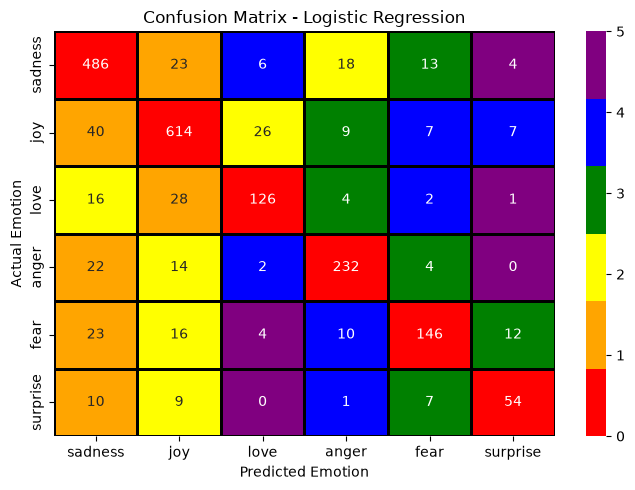

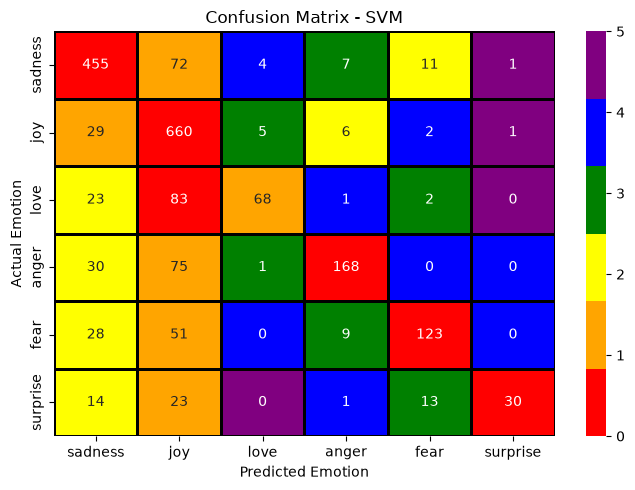

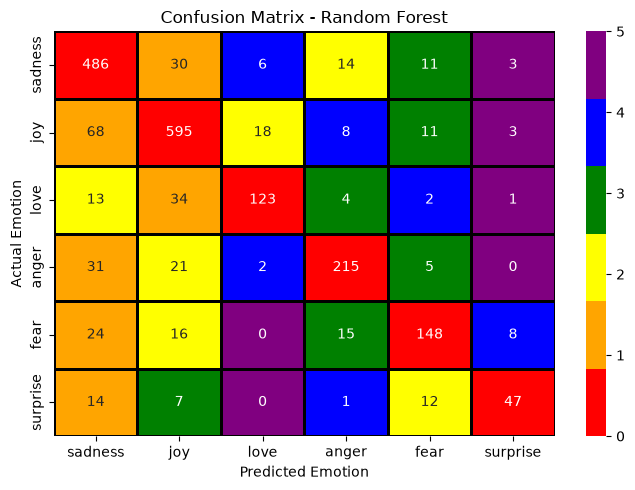

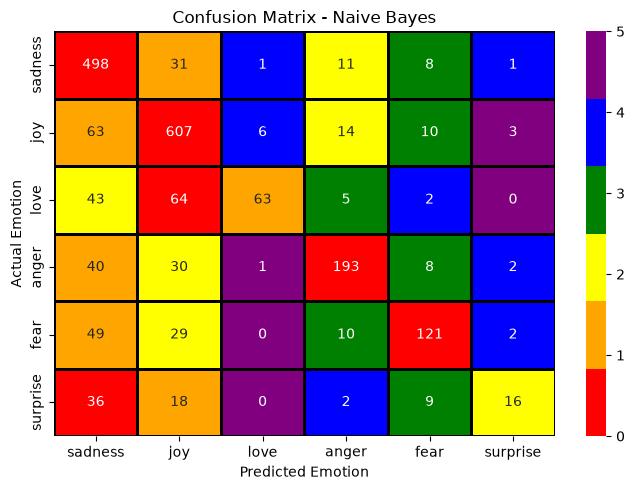

In [65]:
from matplotlib.colors import ListedColormap
for name, y_pred in y_preds.items():

    cm = confusion_matrix(y_val_label,y_pred)

    rank_matrix = np.zeros_like(cm)

    for i, row in enumerate(cm):
        sorted_values = np.sort(np.unique(row))[::-1]

        for rank, value in enumerate(sorted_values):
            rank_matrix[i][row == value] = rank

    colors = [
        "red",       # Highest
        "orange",    # 2nd highest
        "yellow",    # 3rd highest
        "green",     # 4th highest
        "blue",      # 5th highest
        "purple"     # 6th highest
    ]

    cmap = ListedColormap(colors)

    plt.figure(figsize=(7, 5))

    sns.heatmap(
      rank_matrix,
        annot=cm,
        fmt="d",
        cmap=cmap,
        xticklabels=class_name,
        yticklabels=class_name,
        cbar=True,
        linewidths=1,
        linecolor="black"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")

    plt.tight_layout()
    plt.show()

In [66]:
for name, y_pred in y_preds.items():

    cr = classification_report(y_val_label,y_pred,target_names=class_name)
    print(f"classification_report-{name}")
    print(cr)

classification_report-Logistic Regression
              precision    recall  f1-score   support

     sadness       0.81      0.88      0.85       550
         joy       0.87      0.87      0.87       703
        love       0.77      0.71      0.74       177
       anger       0.85      0.85      0.85       274
        fear       0.82      0.69      0.75       211
    surprise       0.69      0.67      0.68        81

    accuracy                           0.83      1996
   macro avg       0.80      0.78      0.79      1996
weighted avg       0.83      0.83      0.83      1996

classification_report-SVM
              precision    recall  f1-score   support

     sadness       0.79      0.83      0.81       550
         joy       0.68      0.94      0.79       703
        love       0.87      0.38      0.53       177
       anger       0.88      0.61      0.72       274
        fear       0.81      0.58      0.68       211
    surprise       0.94      0.37      0.53        81

    accur